# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

## Import packages

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os 
import numpy as np
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '../../src/troutpy_reproducibility'))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from roi_processing import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## Read main path to .zarr file

In [2]:
path_data='/media/sergio/Meninges/troutpy/raw/cosmx_colon/GSE234713'
sdata=spatialdata_io.cosmx(path_data,dataset_id='GSM7473682_HC_a')

output_path = "/media/sergio/Meninges/troutpy/rois/cosmx_hscolon"

INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to 

In [ ]:
### MAIN PROBLEM HERE WAS THAT CELLS IN TILE IN LABELS DID NOT MATCH CELLS IN ADATA

,fov,Area,AspectRatio,Width,Height,Mean.MembraneStain,Max.MembraneStain,Mean.PanCK,Max.PanCK,Mean.CD45,Max.CD45,Mean.CD3,Max.CD3,Mean.DAPI,Max.DAPI,fov_labels,cell_ID
1_1,1,6153,0.67,79,118,680,2218,17170,29735,198,9639,234,1237,20,131,1_labels,1
2_1,1,16178,0.85,137,161,615,4453,16775,29702,222,21371,234,1520,12,122,1_labels,2
3_1,1,3119,1.52,79,52,989,2827,24033,29662,171,6858,298,1721,13,58,1_labels,3
4_1,1,3988,1.52,91,60,449,2099,13575,29651,146,935,206,1402,6,56,1_labels,4
5_1,1,4773,0.53,63,118,1002,2425,24946,29670,299,6387,330,1443,22,116,1_labels,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3517_20,20,3230,1.20,66,55,147,660,109,483,86,687,259,1223,23,244,20_labels,3517
3518_20,20,1390,1.02,46,45,203,626,24,262,133,454,217,834,65,337,20_labels,3518
3519_20,20,3069,2.75,99,36,393,905,2257,8534,165,742,371,2001,41,232,20_labels,3519
3520_20,20,1105,0.93,40,43,360,821,205,823,117,558,575,2495,33,190,20_labels,3520


In [47]:
len(np.unique(sdata['table'].obs.index))

42636

In [ ]:
import numpy as np
import pandas as pd
import copy
import spatialdata as sd
import xarray as xr
from spatialdata.models import Image2DModel, Labels2DModel, TableModel

def process_image_data(sdata: sd.SpatialData) -> xr.DataArray:
    # ... (unchanged) ...
    fov_keys = list(sdata.images.data.keys())
    sample_raw = sdata.images.data[fov_keys[0]].data
    sample = sample_raw.compute() if hasattr(sample_raw, 'compute') else sample_raw
    h, w = sample.shape[1:]
    x_offs, y_offs = {}, {}
    for key in fov_keys:
        M = sdata.images.data[key].transform['global'].matrix
        x_offs[key], y_offs[key] = M[0,2], M[1,2]
    x_min, y_min = min(x_offs.values()), min(y_offs.values())
    x_max = max(x_offs[key] + w for key in fov_keys)
    y_max = max(y_offs[key] + h for key in fov_keys)
    canvas = np.zeros((3, int(np.ceil(y_max - y_min)), int(np.ceil(x_max - x_min))), dtype=np.uint8)
    for key in fov_keys:
        tile_raw = sdata.images.data[key].data
        tile = tile_raw.compute() if hasattr(tile_raw, 'compute') else tile_raw
        x0 = int(round(x_offs[key] - x_min)); y0 = int(round(y_offs[key] - y_min))
        canvas[:, y0:y0+h, x0:x0+w] = tile
    return xr.DataArray(canvas, dims=('c','y','x'))

def process_label_data(sdata: sd.SpatialData) -> (xr.DataArray, dict):
    # ... (unchanged) ...
    fov_keys = list(sdata.labels.data.keys())
    sample_raw = sdata.labels.data[fov_keys[0]].data
    sample = sample_raw.compute() if hasattr(sample_raw, 'compute') else sample_raw
    h, w = sample.shape[:2]
    x_offs, y_offs = {}, {}
    for key in fov_keys:
        M = sdata.labels.data[key].transform['global'].matrix
        x_offs[key], y_offs[key] = M[0,2], M[1,2]
    x_min, y_min = min(x_offs.values()), min(y_offs.values())
    x_max = max(x_offs[key] + w for key in fov_keys)
    y_max = max(y_offs[key] + h for key in fov_keys)
    global_lbl = np.zeros((int(np.ceil(y_max - y_min)), int(np.ceil(x_max - x_min))), dtype=sample.dtype)

    next_id = 1
    id_map = {}
    for key in fov_keys:
        # numeric fov
        fov = int(str(key).split('_',1)[0])
        tile_raw = sdata.labels.data[key].data
        tile = tile_raw.compute() if hasattr(tile_raw, 'compute') else tile_raw
        unique_ids = np.unique(tile[tile > 0])
        tile_map = {(fov, orig): next_id + i for i, orig in enumerate(unique_ids)}
        id_map.update(tile_map)
        next_id += len(unique_ids)
        rel = np.zeros_like(tile)
        for (fv, orig), new in tile_map.items():
            rel[tile == orig] = new
        x0 = int(round(x_offs[key] - x_min)); y0 = int(round(y_offs[key] - y_min))
        sub = global_lbl[y0:y0+h, x0:x0+w]
        mask = (sub == 0) & (rel > 0)
        sub[mask] = rel[mask]
        global_lbl[y0:y0+h, x0:x0+w] = sub
    return xr.DataArray(global_lbl, dims=('y','x')), id_map

def process_transcript_data(sdata: sd.SpatialData) -> pd.DataFrame:
    """
    Concatenate transcript tiles, attach numeric fov parsed from tile key.
    """
    dfs = []
    for key in sdata.points.data.keys():
        # parse numeric fov from tile key
        fov = int(str(key).split('_',1)[0])
        elem = sdata.points.data[key]
        raw = getattr(elem, 'data', elem)
        df = raw.compute() if hasattr(raw, 'compute') else raw
        df = df.copy()
        df['fov'] = fov
        dfs.append(df)
    tx = pd.concat(dfs, ignore_index=True)
    # rename and keep coords
    tx['local_x'] = tx['x']; tx['local_y'] = tx['y']
    tx.drop(columns=['x','y'], inplace=True)
    tx.rename(columns={'x_global_px':'x','y_global_px':'y','target':'gene'}, inplace=True)
    tx.reset_index(drop=True, inplace=True)
    return tx

def cosmx_converter(sdata: sd.SpatialData, copy_data: bool=False) -> sd.SpatialData:
    sdata_out = copy.deepcopy(sdata) if copy_data else sdata

    # 1) stitch images and labels
    img_da = process_image_data(sdata_out)
    lbl_da, id_map = process_label_data(sdata_out)

    # 2) transcripts df
    tx_df = process_transcript_data(sdata_out)

    # 5) shift transcript coords and table spatial coords
    min_x, min_y = tx_df['x'].min(), tx_df['y'].min()
    tx_df['x'] -= min_x; tx_df['y'] -= min_y
    if 'global' in sdata_out.table.obsm:
        sdata_out.table.obsm['spatial'] = sdata_out.table.obsm['global'] - [min_x, min_y]

    # 6) pack back
    sdata_out.images = {
        'morphology_focus': Image2DModel.parse(
            data=img_da,
            scale_factors=(2,2),
            c_coords=sdata_out.images[next(iter(sdata_out.images))].c.data
        )
    }
    sdata_out.labels = {'labels': Labels2DModel.parse(data=lbl_da, scale_factors=(2,2))}
    sdata_out.points = {'transcripts': sd.models.PointsModel.parse(tx_df)}



    return sdata_out,id_map

In [ ]:
import copy
import numpy as np
import pandas as pd
import spatialdata as sd
import xarray as xr
from spatialdata.models import Image2DModel, Labels2DModel, TableModel


def process_image_data(sdata: sd.SpatialData) -> xr.DataArray:
    # ... unchanged stitching logic ...
    fov_keys = list(sdata.images.data.keys())
    sample_raw = sdata.images.data[fov_keys[0]].data
    sample = sample_raw.compute() if hasattr(sample_raw, 'compute') else sample_raw
    h, w = sample.shape[1:]
    x_offs, y_offs = {}, {}
    for key in fov_keys:
        M = sdata.images.data[key].transform['global'].matrix
        x_offs[key], y_offs[key] = M[0,2], M[1,2]
    x_min, y_min = min(x_offs.values()), min(y_offs.values())
    x_max = max(x_offs[key] + w for key in fov_keys)
    y_max = max(y_offs[key] + h for key in fov_keys)
    canvas = np.zeros((3, int(np.ceil(y_max - y_min)), int(np.ceil(x_max - x_min))), dtype=np.uint8)
    for key in fov_keys:
        tile_raw = sdata.images.data[key].data
        tile = tile_raw.compute() if hasattr(tile_raw, 'compute') else tile_raw
        x0 = int(round(x_offs[key] - x_min)); y0 = int(round(y_offs[key] - y_min))
        canvas[:, y0:y0+h, x0:x0+w] = tile
    return xr.DataArray(canvas, dims=('c','y','x'))


def process_label_data(sdata: sd.SpatialData) -> (xr.DataArray, dict):
    # ... unchanged label stitching and id_map generation ...
    fov_keys = list(sdata.labels.data.keys())
    sample_raw = sdata.labels.data[fov_keys[0]].data
    sample = sample_raw.compute() if hasattr(sample_raw, 'compute') else sample_raw
    h, w = sample.shape[:2]
    x_offs, y_offs = {}, {}
    for key in fov_keys:
        M = sdata.labels.data[key].transform['global'].matrix
        x_offs[key], y_offs[key] = M[0,2], M[1,2]
    x_min, y_min = min(x_offs.values()), min(y_offs.values())
    x_max = max(x_offs[key] + w for key in fov_keys)
    y_max = max(y_offs[key] + h for key in fov_keys)
    global_lbl = np.zeros((int(np.ceil(y_max - y_min)), int(np.ceil(x_max - x_min))), dtype=sample.dtype)
    next_id = 1
    id_map = {}
    for key in fov_keys:
        fov = int(str(key).split('_',1)[0])
        tile_raw = sdata.labels.data[key].data
        tile = tile_raw.compute() if hasattr(tile_raw, 'compute') else tile_raw
        unique_ids = np.unique(tile[tile>0])
        tile_map = {(fov, orig): next_id+i for i,orig in enumerate(unique_ids)}
        id_map.update(tile_map)
        next_id += len(unique_ids)
        rel = np.zeros_like(tile)
        for (fv,orig),new in tile_map.items():
            rel[tile==orig] = new
        x0 = int(round(x_offs[key]-x_min)); y0 = int(round(y_offs[key]-y_min))
        sub = global_lbl[y0:y0+h, x0:x0+w]
        mask = (sub==0)&(rel>0)
        sub[mask] = rel[mask]
        global_lbl[y0:y0+h, x0:x0+w] = sub
    return xr.DataArray(global_lbl, dims=('y','x')), id_map


def process_transcript_data(sdata: sd.SpatialData) -> pd.DataFrame:
    # ... unchanged transcript concatenation with fov col ...
    dfs = []
    for key in sdata.points.data.keys():
        fov = int(str(key).split('_',1)[0])
        elem = sdata.points.data[key]
        raw = elem.data if hasattr(elem,'data') else elem
        df = raw.compute() if hasattr(raw,'compute') else raw
        df = df.copy()
        df['fov'] = fov
        dfs.append(df)
    tx = pd.concat(dfs, ignore_index=True)
    tx['local_x'] = tx['x']; tx['local_y'] = tx['y']
    tx.drop(columns=['x','y'], inplace=True)
    tx.rename(columns={'x_global_px':'x','y_global_px':'y','target':'gene'}, inplace=True)
    tx['transcript_id'] = np.arange(len(tx))
    tx['overlaps_cell'] = tx['cell_ID'] != 0
    tx['overlaps_nuclei'] = tx['CellComp']=='Nuclear'
    tx['overlaps_nuclei'].fillna(False, inplace=True)
    tx['control_probe'] = tx['gene'].str.startswith('NegPrb')
    if 'global' in sdata['table'].obsm:
        sdata['table'].obsm['spatial'] = sdata['table'].obsm['global'].copy()
    return tx


def cosmx_converter(sdata: sd.SpatialData, copy_data: bool=False) -> sd.SpatialData:
    """Main converter: stitches, remaps cell_IDs via string-combined mapping."""
    sdata_out = copy.deepcopy(sdata) if copy_data else sdata
    # 1) stitch
    img_da = process_image_data(sdata_out)
    lbl_da, id_map = process_label_data(sdata_out)
    # 2) transcripts
    tx_df = process_transcript_data(sdata_out)
    # 3) create string-keyed mapping
    dict_new = {f"{fov}_{orig}": new for (fov,orig), new in id_map.items()}
    # 4) remap transcripts using combined key
    tx_df['unique_id'] = tx_df['fov'].astype(int).astype(str) + '_' + tx_df['cell_ID'].astype(int).astype(str)
    tx_df['cell_ID'] = tx_df['unique_id'].map(dict_new).fillna(0).astype(int)
    tx_df.drop(columns=['unique_id'], inplace=True)
    # 5) remap table via index
    sdata_out['table'].obs['unique_id'] =sdata_out['table'].obs['fov'].astype(int).astype(str) + '_' + sdata_out['table'].obs['cell_ID'].astype(int).astype(str)
    sdata_out['table'].obs['cell_ID'] = sdata_out['table'].obs['unique_id'].map(dict_new).fillna(0).astype(int)

    # 6) shift coords
    min_x, min_y = tx_df['x'].min(), tx_df['y'].min()
    tx_df['x'] -= min_x; tx_df['y'] -= min_y
    if 'spatial' in sdata_out.table.obsm:
        sdata_out.table.obsm['spatial'][:,0] -= min_x
        sdata_out.table.obsm['spatial'][:,1] -= min_y
    # 7) pack models
    sdata_out.images = {'morphology_focus': Image2DModel.parse(
        data=img_da, scale_factors=(2,2), c_coords=sdata_out[list(sdata_out.images.keys())[0]].c.data
    )}
    sdata_out.labels = {'labels': Labels2DModel.parse(data=lbl_da, scale_factors=(2,2))}
    sdata_out.points = {'transcripts': sd.models.PointsModel.parse(tx_df)}
    # 8) shapes + metadata
    sdata_out['shapes'] = sd.to_polygons(sdata_out.labels['labels'])
    sdata_out['shapes'].index = sdata_out['shapes'].index.astype(int)
    orig_table = sdata_out['table'].copy()
    orig_table.uns.pop(TableModel.ATTRS_KEY, None)
    orig_table.obs['region'] = 'shapes'
    # re-parse that AnnData into a SpatialData table layer
    sdata_out["table"] = TableModel.parse(
        orig_table,
        region="shapes",  # or whatever region_key you want
        region_key="region",
        instance_key="cell_ID",
    )
    return sdata_out if copy_data else None



In [4]:
sdata,id_map=cosmx_converter(sdata)

In [49]:
unique_id

NameError: name 'unique_id' is not defined

In [52]:
i

NameError: name 'i' is not defined

In [56]:
sdata['table'].obs['fov'].unique()

['1', '2', '3', '4', '5', ..., '15', '16', '18', '19', '20']
Length: 19
Categories (19, object): ['1', '10', '11', '12', ..., '6', '7', '8', '9']

In [54]:
sdata

SpatialData object
├── Images
│     ├── '1_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '2_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '3_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '4_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '5_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '6_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '7_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '8_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '9_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '10_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '11_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '12_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '13_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '14_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '15_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '16_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '18_image': DataArray[cyx] (3, 3648, 5472)
│     ├── '19_image': DataArray[cyx] (3, 3648, 5472)
│     └── '20_image': Dat

In [50]:
for key in fov_keys:
    fov = int(str(key).split('_',1)[0])
    tile_raw = sdata.labels.data[key].data
    tile = tile_raw.compute() if hasattr(tile_raw, 'compute') else tile_raw
    unique_ids = np.unique(tile[tile>0])
    tile_map = {(fov, orig): next_id+i for i,orig in enumerate(unique_ids)}
    id_map.update(tile_map)
    next_id += len(unique_ids)
    rel = np.zeros_like(tile)
    for (fv,orig),new in tile_map.items():
        rel[tile==orig] = new
    x0 = int(round(x_offs[key]-x_min)); y0 = int(round(y_offs[key]-y_min))
    sub = global_lbl[y0:y0+h, x0:x0+w]
    mask = (sub==0)&(rel>0)
    sub[mask] = rel[mask]
    global_lbl[y0:y0+h, x0:x0+w] = sub

KeyboardInterrupt: 

In [53]:
unique_ids

array([   1,    2,    3, ..., 1514, 1515, 1516], dtype=uint16)

In [ ]:
allg=0
for key in fov_keys:
    fov = int(str(key).split('_',1)[0])
    print()
    tile_raw = sdata.labels.data[key].data
    tile = tile_raw.compute() if hasattr(tile_raw, 'compute') else tile_raw
    unique_ids = np.unique(tile[tile>0])
    allg=allg+len(unique_ids)

In [8]:
dict_new = {f"{fov}_{orig}": new for (fov,orig), new in id_map.items()}

In [20]:
list(dict_new.values())[1000]

1001

In [29]:
list(sdata['table'].obs['unique_id'])[1500:]

['1_1501',
 '1_1502',
 '1_1503',
 '1_1504',
 '1_1505',
 '1_1506',
 '1_1507',
 '1_1508',
 '1_1509',
 '1_1510',
 '1_1511',
 '1_1512',
 '1_1513',
 '1_1514',
 '1_1515',
 '1_1516',
 '1_1517',
 '1_1518',
 '1_1519',
 '1_1520',
 '1_1521',
 '1_1522',
 '1_1523',
 '1_1524',
 '1_1525',
 '1_1526',
 '1_1527',
 '1_1528',
 '1_1529',
 '1_1530',
 '1_1531',
 '1_1532',
 '1_1533',
 '1_1534',
 '1_1535',
 '1_1536',
 '1_1537',
 '1_1538',
 '1_1539',
 '1_1540',
 '1_1541',
 '1_1542',
 '1_1543',
 '1_1544',
 '1_1545',
 '1_1546',
 '1_1547',
 '1_1548',
 '1_1549',
 '1_1550',
 '1_1551',
 '1_1552',
 '1_1553',
 '1_1554',
 '1_1555',
 '1_1556',
 '1_1557',
 '1_1558',
 '1_1559',
 '1_1560',
 '1_1561',
 '1_1562',
 '1_1563',
 '1_1564',
 '1_1565',
 '1_1566',
 '1_1567',
 '1_1568',
 '1_1569',
 '1_1570',
 '1_1571',
 '1_1572',
 '1_1573',
 '1_1574',
 '1_1575',
 '1_1576',
 '1_1577',
 '1_1578',
 '1_1579',
 '1_1580',
 '1_1581',
 '1_1582',
 '1_1583',
 '1_1584',
 '1_1585',
 '1_1586',
 '1_1587',
 '1_1588',
 '1_1589',
 '1_1590',
 '1_1591',

In [28]:
list(sdata['table'].obs['unique_id'].map(dict_new))[1500:]

[1501.0,
 1502.0,
 1503.0,
 1504.0,
 1505.0,
 1506.0,
 1507.0,
 1508.0,
 1509.0,
 1510.0,
 1511.0,
 1512.0,
 1513.0,
 1514.0,
 1515.0,
 1516.0,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan

In [ ]:
sdata['table'].obs['unique_id'] =sdata['table'].obs['fov'].astype(int).astype(str) + '_' + sdata['table'].obs['cell_ID'].astype(int).astype(str)

In [31]:
list(dict_new.keys())[1500:]

['1_1501',
 '1_1502',
 '1_1503',
 '1_1504',
 '1_1505',
 '1_1506',
 '1_1507',
 '1_1508',
 '1_1509',
 '1_1510',
 '1_1511',
 '1_1512',
 '1_1513',
 '1_1514',
 '1_1515',
 '1_1516',
 '2_1',
 '2_2',
 '2_3',
 '2_4',
 '2_5',
 '2_6',
 '2_7',
 '2_8',
 '2_9',
 '2_10',
 '2_11',
 '2_12',
 '2_13',
 '2_14',
 '2_15',
 '2_16',
 '2_17',
 '2_18',
 '2_19',
 '2_20',
 '2_21',
 '2_22',
 '2_23',
 '2_24',
 '2_25',
 '2_26',
 '2_27',
 '2_28',
 '2_29',
 '2_30',
 '2_31',
 '2_32',
 '2_33',
 '2_34',
 '2_35',
 '2_36',
 '2_37',
 '2_38',
 '2_39',
 '2_40',
 '2_41',
 '2_42',
 '2_43',
 '2_44',
 '2_45',
 '2_46',
 '2_47',
 '2_48',
 '2_49',
 '2_50',
 '2_51',
 '2_52',
 '2_53',
 '2_54',
 '2_55',
 '2_56',
 '2_57',
 '2_58',
 '2_59',
 '2_60',
 '2_61',
 '2_62',
 '2_63',
 '2_64',
 '2_65',
 '2_66',
 '2_67',
 '2_68',
 '2_69',
 '2_70',
 '2_71',
 '2_72',
 '2_73',
 '2_74',
 '2_75',
 '2_76',
 '2_77',
 '2_78',
 '2_79',
 '2_80',
 '2_81',
 '2_82',
 '2_83',
 '2_84',
 '2_85',
 '2_86',
 '2_87',
 '2_88',
 '2_89',
 '2_90',
 '2_91',
 '2_92',
 '2_9

In [30]:
list(dict_new.values())[1500:]

[1501,
 1502,
 1503,
 1504,
 1505,
 1506,
 1507,
 1508,
 1509,
 1510,
 1511,
 1512,
 1513,
 1514,
 1515,
 1516,
 1517,
 1518,
 1519,
 1520,
 1521,
 1522,
 1523,
 1524,
 1525,
 1526,
 1527,
 1528,
 1529,
 1530,
 1531,
 1532,
 1533,
 1534,
 1535,
 1536,
 1537,
 1538,
 1539,
 1540,
 1541,
 1542,
 1543,
 1544,
 1545,
 1546,
 1547,
 1548,
 1549,
 1550,
 1551,
 1552,
 1553,
 1554,
 1555,
 1556,
 1557,
 1558,
 1559,
 1560,
 1561,
 1562,
 1563,
 1564,
 1565,
 1566,
 1567,
 1568,
 1569,
 1570,
 1571,
 1572,
 1573,
 1574,
 1575,
 1576,
 1577,
 1578,
 1579,
 1580,
 1581,
 1582,
 1583,
 1584,
 1585,
 1586,
 1587,
 1588,
 1589,
 1590,
 1591,
 1592,
 1593,
 1594,
 1595,
 1596,
 1597,
 1598,
 1599,
 1600,
 1601,
 1602,
 1603,
 1604,
 1605,
 1606,
 1607,
 1608,
 1609,
 1610,
 1611,
 1612,
 1613,
 1614,
 1615,
 1616,
 1617,
 1618,
 1619,
 1620,
 1621,
 1622,
 1623,
 1624,
 1625,
 1626,
 1627,
 1628,
 1629,
 1630,
 1631,
 1632,
 1633,
 1634,
 1635,
 1636,
 1637,
 1638,
 1639,
 1640,
 1641,
 1642,
 1643,

In [14]:
sdata['table'].obs

,fov,Area,AspectRatio,Width,Height,Mean.MembraneStain,Max.MembraneStain,Mean.PanCK,Max.PanCK,Mean.CD45,Max.CD45,Mean.CD3,Max.CD3,Mean.DAPI,Max.DAPI,fov_labels,cell_ID,unique_id
1_1,1,6153,0.67,79,118,680,2218,17170,29735,198,9639,234,1237,20,131,1_labels,1,1_1
2_1,1,16178,0.85,137,161,615,4453,16775,29702,222,21371,234,1520,12,122,1_labels,2,1_2
3_1,1,3119,1.52,79,52,989,2827,24033,29662,171,6858,298,1721,13,58,1_labels,3,1_3
4_1,1,3988,1.52,91,60,449,2099,13575,29651,146,935,206,1402,6,56,1_labels,4,1_4
5_1,1,4773,0.53,63,118,1002,2425,24946,29670,299,6387,330,1443,22,116,1_labels,5,1_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3517_20,20,3230,1.20,66,55,147,660,109,483,86,687,259,1223,23,244,20_labels,0,20_3517
3518_20,20,1390,1.02,46,45,203,626,24,262,133,454,217,834,65,337,20_labels,0,20_3518
3519_20,20,3069,2.75,99,36,393,905,2257,8534,165,742,371,2001,41,232,20_labels,0,20_3519
3520_20,20,1105,0.93,40,43,360,821,205,823,117,558,575,2495,33,190,20_labels,0,20_3520


In [6]:
id_map

{(1, 1): 1,
 (1, 2): 2,
 (1, 3): 3,
 (1, 4): 4,
 (1, 5): 5,
 (1, 6): 6,
 (1, 7): 7,
 (1, 8): 8,
 (1, 9): 9,
 (1, 10): 10,
 (1, 11): 11,
 (1, 12): 12,
 (1, 13): 13,
 (1, 14): 14,
 (1, 15): 15,
 (1, 16): 16,
 (1, 17): 17,
 (1, 18): 18,
 (1, 19): 19,
 (1, 20): 20,
 (1, 21): 21,
 (1, 22): 22,
 (1, 23): 23,
 (1, 24): 24,
 (1, 25): 25,
 (1, 26): 26,
 (1, 27): 27,
 (1, 28): 28,
 (1, 29): 29,
 (1, 30): 30,
 (1, 31): 31,
 (1, 32): 32,
 (1, 33): 33,
 (1, 34): 34,
 (1, 35): 35,
 (1, 36): 36,
 (1, 37): 37,
 (1, 38): 38,
 (1, 39): 39,
 (1, 40): 40,
 (1, 41): 41,
 (1, 42): 42,
 (1, 43): 43,
 (1, 44): 44,
 (1, 45): 45,
 (1, 46): 46,
 (1, 47): 47,
 (1, 48): 48,
 (1, 49): 49,
 (1, 50): 50,
 (1, 51): 51,
 (1, 52): 52,
 (1, 53): 53,
 (1, 54): 54,
 (1, 55): 55,
 (1, 56): 56,
 (1, 57): 57,
 (1, 58): 58,
 (1, 59): 59,
 (1, 60): 60,
 (1, 61): 61,
 (1, 62): 62,
 (1, 63): 63,
 (1, 64): 64,
 (1, 65): 65,
 (1, 66): 66,
 (1, 67): 67,
 (1, 68): 68,
 (1, 69): 69,
 (1, 70): 70,
 (1, 71): 71,
 (1, 72): 72,
 (1, 73): 

In [43]:
orig_table = sdata['table'].copy()
orig_table = sdata['table'].copy()
orig_table.obs['region'] = 'shapes'

In [46]:
orig_table.obs

,fov,Area,AspectRatio,Width,Height,Mean.MembraneStain,Max.MembraneStain,Mean.PanCK,Max.PanCK,Mean.CD45,Max.CD45,Mean.CD3,Max.CD3,Mean.DAPI,Max.DAPI,fov_labels,cell_ID,unique_id,region
1_1,1,6153,0.67,79,118,680,2218,17170,29735,198,9639,234,1237,20,131,1_labels,1,1_1,shapes
2_1,1,16178,0.85,137,161,615,4453,16775,29702,222,21371,234,1520,12,122,1_labels,2,1_2,shapes
3_1,1,3119,1.52,79,52,989,2827,24033,29662,171,6858,298,1721,13,58,1_labels,3,1_3,shapes
4_1,1,3988,1.52,91,60,449,2099,13575,29651,146,935,206,1402,6,56,1_labels,4,1_4,shapes
5_1,1,4773,0.53,63,118,1002,2425,24946,29670,299,6387,330,1443,22,116,1_labels,5,1_5,shapes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3517_20,20,3230,1.20,66,55,147,660,109,483,86,687,259,1223,23,244,20_labels,0,20_3517,shapes
3518_20,20,1390,1.02,46,45,203,626,24,262,133,454,217,834,65,337,20_labels,0,20_3518,shapes
3519_20,20,3069,2.75,99,36,393,905,2257,8534,165,742,371,2001,41,232,20_labels,0,20_3519,shapes
3520_20,20,1105,0.93,40,43,360,821,205,823,117,558,575,2495,33,190,20_labels,0,20_3520,shapes


In [ ]:
orig_table.uns.pop(TableModel.ATTRS_KEY, None)

{'region': ['1_labels',
  '12_labels',
  '6_labels',
  '9_labels',
  '7_labels',
  '10_labels',
  '19_labels',
  '20_labels',
  '14_labels',
  '5_labels',
  '3_labels',
  '8_labels',
  '2_labels',
  '15_labels',
  '4_labels',
  '16_labels',
  '13_labels',
  '18_labels',
  '11_labels'],
 'region_key': 'fov_labels',
 'instance_key': 'cell_ID'}

In [23]:
sdata['shapes']['label']=sdata['shapes']['label'].astype(int)

In [24]:
sdata_out.table = TableModel.parse(
        orig_table, region='shapes', region_key='region', instance_key='cell_ID'
    )

ValueError: Instance key column for region(s) `shapes` does not contain only unique values

In [29]:
sdata['table'].obs['cell_ID'].head(200)

1_1          1
2_1       1517
3_1       5723
4_1       9806
5_1      12914
         ...  
196_1        0
197_1        0
198_1        0
199_1        0
200_1        0
Name: cell_ID, Length: 200, dtype: int64

In [ ]:
sdata['table'].obs['cell_ID']

AnnData object with n_obs × n_vars = 42636 × 999
    obs: 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'fov_labels', 'cell_ID'
    uns: 'spatialdata_attrs'
    obsm: 'global', 'spatial'

In [ ]:
dict_new={}
keys=list(id_map.keys())
vals=list(id_map.values())
for n in range(len(id_map)):
   comb=str(int(keys[n][0]))+'_'+str(int(keys[n][1]))
   dict_new[comb]=vals[n]
#####

tran=sdata['transcripts'].compute()
tran['unique_id']=tran['fov'].astype(int).astype(str)+'_'+tran['cell_ID'].astype(int).astype(str)
tran['cell_id']=tran['unique_id'].map(dict_new)

#####
sdata.points ['transcripts']= sd.models.PointsModel.parse(tran)
sdata['table'].obs['cell_ID']=sdata['table'].obs.index.map(dict_new)

,gene,cell_ID,y,z_raw,fov,CellComp,x,local_x,local_y
0,REG1A,0,44656.495556,-1,1,<NA>,29853.686111,3202.20,2317.78
1,NegPrb18,0,43601.435556,-1,1,<NA>,28148.926111,1497.44,1262.72
2,CD24,0,43457.645556,-1,1,<NA>,29835.506111,3184.02,1118.93
3,GZMB,0,43771.665556,-1,1,<NA>,29397.216111,2745.73,1432.95
4,REG1A,0,43805.615556,-1,1,<NA>,29003.486111,2352.00,1466.90
...,...,...,...,...,...,...,...,...,...
9531236,LYZ,3521,16697.858889,7,20,Cytoplasm,36282.423889,3953.16,25.81
9531237,NEAT1,3521,16698.148889,7,20,Cytoplasm,36292.463889,3963.20,26.10
9531238,MALAT1,3521,16690.488889,7,20,Cytoplasm,36295.953889,3966.69,18.44
9531239,LTBR,3521,16693.458889,7,20,Nuclear,36270.203889,3940.94,21.41


In [ ]:
sdata

SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (3, 46004, 37811), (3, 23002, 18905), (3, 11501, 9452)
├── Labels
│     └── 'labels': DataTree[yx] (46004, 32134), (23002, 16067), (11501, 8033)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 9) (2D points)
└── Tables
      └── 'table': AnnData (42636, 999)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), labels (Labels), transcripts (Points)

In [ ]:
# 7) shapes and table re-attach
sdata['shapes'] = sd.to_polygons(sdata.labels['labels'])
sdata['shapes'].index = sdata['shapes'].index.astype(int)
sdata['shapes']['label']=sdata['shapes']['label'].astype(int)

In [23]:
sdata['table'].obs['region']='shapes'

In [31]:
sdata['transcripts']['cell_ID'].compute()

0          0
1          0
2          0
3          0
4          0
          ..
9531236    0
9531237    0
9531238    0
9531239    0
9531240    0
Name: cell_ID, Length: 9531241, dtype: int64

In [29]:
id_map

{(1, 1): 1,
 (1, 2): 2,
 (1, 3): 3,
 (1, 4): 4,
 (1, 5): 5,
 (1, 6): 6,
 (1, 7): 7,
 (1, 8): 8,
 (1, 9): 9,
 (1, 10): 10,
 (1, 11): 11,
 (1, 12): 12,
 (1, 13): 13,
 (1, 14): 14,
 (1, 15): 15,
 (1, 16): 16,
 (1, 17): 17,
 (1, 18): 18,
 (1, 19): 19,
 (1, 20): 20,
 (1, 21): 21,
 (1, 22): 22,
 (1, 23): 23,
 (1, 24): 24,
 (1, 25): 25,
 (1, 26): 26,
 (1, 27): 27,
 (1, 28): 28,
 (1, 29): 29,
 (1, 30): 30,
 (1, 31): 31,
 (1, 32): 32,
 (1, 33): 33,
 (1, 34): 34,
 (1, 35): 35,
 (1, 36): 36,
 (1, 37): 37,
 (1, 38): 38,
 (1, 39): 39,
 (1, 40): 40,
 (1, 41): 41,
 (1, 42): 42,
 (1, 43): 43,
 (1, 44): 44,
 (1, 45): 45,
 (1, 46): 46,
 (1, 47): 47,
 (1, 48): 48,
 (1, 49): 49,
 (1, 50): 50,
 (1, 51): 51,
 (1, 52): 52,
 (1, 53): 53,
 (1, 54): 54,
 (1, 55): 55,
 (1, 56): 56,
 (1, 57): 57,
 (1, 58): 58,
 (1, 59): 59,
 (1, 60): 60,
 (1, 61): 61,
 (1, 62): 62,
 (1, 63): 63,
 (1, 64): 64,
 (1, 65): 65,
 (1, 66): 66,
 (1, 67): 67,
 (1, 68): 68,
 (1, 69): 69,
 (1, 70): 70,
 (1, 71): 71,
 (1, 72): 72,
 (1, 73): 

In [25]:
sdata['table'].obs['cell_ID']

1_1        0
2_1        0
3_1        0
4_1        0
5_1        0
          ..
3517_20    0
3518_20    0
3519_20    0
3520_20    0
3521_20    0
Name: cell_ID, Length: 42636, dtype: int64

In [ ]:
# re-parse table
original_table = sdata.table.copy()
original_table.uns.pop(TableModel.ATTRS_KEY, None)
original_table.obs['region'] = 'shapes'


sdata.table = TableModel.parse(original_table,region='shapes', region_key='region', instance_key='cell_ID')

ValueError: Instance key column for region(s) `shapes` does not contain only unique values

In [4]:
sdata['table'].obs['cell_ID']

1_1        1
2_1        2
3_1        3
4_1        4
5_1        5
          ..
3517_20    0
3518_20    0
3519_20    0
3520_20    0
3521_20    0
Name: cell_ID, Length: 42636, dtype: int64

In [ ]:
# ROI selection
bb_xmin = 12000# mix x 
bb_ymin= 10000 #min y
bb_xmax= 17600 # max x
bb_ymax=14200 # max y

plot_spatial_with_box_and_scale(
    spatial_coords=sdata['table'].obsm['spatial'],
    bb_xmin=bb_xmin,
    bb_xmax=bb_xmax,
    bb_ymin=bb_ymin,
    bb_ymax=bb_ymax, pixel_size_um=1
)

In [ ]:
sdata['table'].obs['x']=[s[0] for s in sdata['table'].obsm['spatial']]
sdata['table'].obs['y']=[s[1] for s in sdata['table'].obsm['spatial']]

cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],target_coordinate_system='global')

In [ ]:
# Save metadata
metadata = generate_metadata(sdata=cropped_sdata,
    sample_id="human_colon",
    species="Homo Sapiens",technology="CosMx",
    segmentation_method="cosmx-default",roi_name="roi_colon",
    tissue="Colon",disease="None")

rechunk_sdata(cropped_sdata)


In [ ]:
# Define output paths
zarr_path = os.path.join(output_path,"data.zarr")
metadata_path = os.path.join(output_path,"metadata.csv")

cropped_sdata.write(zarr_path,overwrite=True)
metadata.to_csv(metadata_path, index=False)

## Deprecated code for converting cosmx data to standard troutpy data

In [ ]:
import numpy as np
import xarray as xr
from spatial_image import to_spatial_image

# Assuming each tile is the same size (e.g., from tile "1_image")
tile_ids=list(sdata.images.data.keys())
tile_ids_image=tile_ids
sample_tile = sdata[tile_ids[0]]
tile_height = sample_tile.data.shape[1]  # e.g., 3648
tile_width  = sample_tile.data.shape[2]  # e.g., 5472

# Extract global offsets from the transformation matrix for each tile
x_offsets = {}
y_offsets = {}
for tid in tile_ids:
    # Access the transformation matrix
    transform_matrix = sdata[tid].transform['global'].matrix
    x_offsets[tid] = transform_matrix[0, 2]
    y_offsets[tid] = transform_matrix[1, 2]

# Compute the global canvas extents using the offsets
global_x_min = min(x_offsets.values())
global_y_min = min(y_offsets.values())
global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

canvas_width  = int(np.ceil(global_x_max - global_x_min))
canvas_height = int(np.ceil(global_y_max - global_y_min))

print("Global Canvas Dimensions: Width =", canvas_width, ", Height =", canvas_height)

# Initialize a canvas for the stitched image (assuming 3-channel RGB)
global_image_canvas = np.zeros((3, canvas_height, canvas_width), dtype=np.uint8)

# Stitch each tile into the global canvas
for tid in tile_ids:
    # Compute the offset relative to the global minimum positions
    x_offset = int(np.round(x_offsets[tid] - global_x_min))
    y_offset = int(np.round(y_offsets[tid] - global_y_min))
    
    # Retrieve the tile image data (expected shape: (3, tile_height, tile_width))
    tile_image = sdata[tid].data

    # Place the tile into the global canvas
    global_image_canvas[:, y_offset:y_offset+tile_height, x_offset:x_offset+tile_width] = tile_image

# Convert the stitched image array to an xarray DataArray and then to a spatial image object
stitched_da = xr.DataArray(global_image_canvas, dims=("c", "y", "x"))

print("Stitching complete!")


Global Canvas Dimensions: Width = 37811 , Height = 46004
Stitching complete!


In [ ]:
import numpy as np
import xarray as xr
#from spatialdata import Label

# Assuming each label tile is the same size (e.g., from tile "1_labels")
tile_ids=list(sdata.labels.data.keys())
#sample_tile = sdata[tile_ids[0]]
sample_label = sdata[tile_ids[0]]
tile_height = sample_label.data.shape[0]  # (y dimension), e.g., 3648
tile_width  = sample_label.data.shape[1]  # (x dimension), e.g., 5472

# Extract global offsets for each tile from the corresponding image's transformation matrix.
# (Labels are aligned with images, so we use sdata[f"{tid}_image"].transform)
x_offsets = {}
y_offsets = {}
for tid in tile_ids:
    # Get the transformation matrix from the associated image tile
    transform_matrix = sdata[f"{tid}"].transform['global'].matrix
    x_offsets[tid] = transform_matrix[0, 2]
    y_offsets[tid] = transform_matrix[1, 2]

# Compute the overall extents of the global canvas for labels
global_x_min = min(x_offsets.values())
global_y_min = min(y_offsets.values())
global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

canvas_width  = int(np.ceil(global_x_max - global_x_min))
canvas_height = int(np.ceil(global_y_max - global_y_min))

print("Global Canvas Dimensions (Labels): Width =", canvas_width, ", Height =", canvas_height)

# Initialize a canvas for the stitched label image
global_label_canvas = np.zeros((canvas_height, canvas_width), dtype=sample_label.data.dtype)

# Place each label tile into the global canvas using its computed offsets
for tid in tile_ids:
    x_offset = int(np.round(x_offsets[tid] - global_x_min))
    y_offset = int(np.round(y_offsets[tid] - global_y_min))
    
    tile_label = sdata[f"{tid}"].data  # shape: (tile_height, tile_width)
    
    # Place the tile's labels into the global canvas
    global_label_canvas[y_offset:y_offset+tile_height, x_offset:x_offset+tile_width] = tile_label

# Wrap the stitched labels into an xarray DataArray
stitched_labels_da = xr.DataArray(global_label_canvas, dims=("y", "x"))

# Optionally, convert the DataArray to a proper Label object (if using spatialdata Label methods)
#stitched_label_object = Label.from_xarray(stitched_labels_da)

print("Label stitching complete!")


Global Canvas Dimensions (Labels): Width = 32134 , Height = 46004
Label stitching complete!


In [155]:
import pandas as pd

alldf = []
for id in tile_ids:
    transcripts = sdata[id].compute()
    alldf.append(transcripts)

# Concatenate all tile dataframes
alltranscripts = pd.concat(alldf, ignore_index=True)

# Store original local coordinates
alltranscripts['local_x'] = alltranscripts['x']
alltranscripts['local_y'] = alltranscripts['y']

del alltranscripts['y']
del alltranscripts['x']

# Rename global coordinates and target
alltranscripts.rename(columns={
    'x_global_px': 'x',
    'y_global_px': 'y',
    'target': 'gene'
}, inplace=True)

# Generate unique transcript_id
alltranscripts['transcript_id'] = [i for i in range(len(alltranscripts))]

# overlaps_cell is True if cell_ID is not 0
alltranscripts['overlaps_cell'] = alltranscripts['cell_ID'] != 0

# overlaps_nuclei is True if CellComp is 'Nuclear'
alltranscripts['overlaps_nuclei'] = alltranscripts['CellComp'] == 'Nuclear'
alltranscripts['overlaps_nuclei'].fillna(False,inplace=True)
alltranscripts['overlaps_nuclei']=alltranscripts['overlaps_nuclei'].astype(bool)

# control_probe is True if gene starts with 'NegPrb'
alltranscripts['control_probe'] = alltranscripts['gene'].str.startswith('NegPrb')


In [ ]:
### format sdata table
sdata['table'].obsm['spatial']=sdata['table'].obsm['global']

In [177]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import spatialdata as sd
import spatialdata_plot as sdp  # noqa: F401
import squidpy as sq
from shapely.geometry import Point
from spatialdata.models import Image2DModel, Labels2DModel

img_for_sdata = Image2DModel.parse(data=stitched_da, scale_factors=(2,2),c_coords=sdata[tile_ids_image[0]].c.data)
parsed_transcripts=sd.models.PointsModel.parse(alltranscripts)
labels_for_sdata = Labels2DModel.parse(data=stitched_labels_da, scale_factors=(2,2))

sdata2 = sd.SpatialData(
    images={"morphology_focus": img_for_sdata},
    labels={"labels": labels_for_sdata},
    tables={"adata": sdata['table']},
    points={"transcripts": parsed_transcripts},
)


NameError: name 'tile_ids_image' is not defined

In [ ]:
import numpy as np
import xarray as xr
from spatial_image import to_spatial_image
import pandas as pd
import spatialdata as sd
from spatialdata.models import Image2DModel, Labels2DModel
from typing import Optional


def process_image_data(sdata: sd.SpatialData) -> xr.DataArray:
    """
    Stitches image tiles from SpatialData object into a single global image.

    Args:
        sdata: The input SpatialData object containing image tiles.

    Returns:
        An xarray DataArray representing the stitched global image.
    """
    tile_ids = list(sdata.images.data.keys())
    sample_tile = sdata[tile_ids[0]]
    tile_height = sample_tile.data.shape[1]
    tile_width = sample_tile.data.shape[2]

    x_offsets = {}
    y_offsets = {}
    for tid in tile_ids:
        transform_matrix = sdata[tid].transform['global'].matrix
        x_offsets[tid] = transform_matrix[0, 2]
        y_offsets[tid] = transform_matrix[1, 2]

    global_x_min = min(x_offsets.values())
    global_y_min = min(y_offsets.values())
    global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
    global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

    canvas_width = int(np.ceil(global_x_max - global_x_min))
    canvas_height = int(np.ceil(global_y_max - global_y_min))

    print(f"Global Image Canvas Dimensions: Width = {canvas_width}, Height = {canvas_height}")

    global_image_canvas = np.zeros((3, canvas_height, canvas_width), dtype=np.uint8)

    for tid in tile_ids:
        x_offset = int(np.round(x_offsets[tid] - global_x_min))
        y_offset = int(np.round(y_offsets[tid] - global_y_min))
        tile_image = sdata[tid].data
        global_image_canvas[:, y_offset:y_offset + tile_height, x_offset:x_offset + tile_width] = tile_image

    stitched_da = xr.DataArray(global_image_canvas, dims=("c", "y", "x"))
    print("Image stitching complete!")
    return stitched_da

def process_label_data(sdata: sd.SpatialData) -> xr.DataArray:
    """
    Stitches label tiles from SpatialData object into a single global label image.

    Args:
        sdata: The input SpatialData object containing label tiles.

    Returns:
        An xarray DataArray representing the stitched global label image.
    """
    tile_ids = list(sdata.labels.data.keys())
    sample_label = sdata[tile_ids[0]]
    tile_height = sample_label.data.shape[0]
    tile_width = sample_label.data.shape[1]

    x_offsets = {}
    y_offsets = {}
    for tid in tile_ids:
        transform_matrix = sdata[f"{tid}"].transform['global'].matrix
        x_offsets[tid] = transform_matrix[0, 2]
        y_offsets[tid] = transform_matrix[1, 2]

    global_x_min = min(x_offsets.values())
    global_y_min = min(y_offsets.values())
    global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
    global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

    canvas_width = int(np.ceil(global_x_max - global_x_min))
    canvas_height = int(np.ceil(global_y_max - global_y_min))

    print(f"Global Label Canvas Dimensions: Width = {canvas_width}, Height = {canvas_height}")

    global_label_canvas = np.zeros((canvas_height, canvas_width), dtype=sample_label.data.dtype)

    for tid in tile_ids:
        x_offset = int(np.round(x_offsets[tid] - global_x_min))
        y_offset = int(np.round(y_offsets[tid] - global_y_min))
        tile_label = sdata[f"{tid}"].data
        global_label_canvas[y_offset:y_offset + tile_height, x_offset:x_offset + tile_width] = tile_label

    stitched_labels_da = xr.DataArray(global_label_canvas, dims=("y", "x"))
    print("Label stitching complete!")
    return stitched_labels_da

def process_transcript_data(sdata: sd.SpatialData) -> pd.DataFrame:
    """
    Processes transcript data from SpatialData object, concatenating tiles and
    performing necessary transformations.

    Args:
        sdata: The input SpatialData object containing transcript data.

    Returns:
        A pandas DataFrame containing the processed transcript data.
    """
    tile_ids = list(sdata.points.data.keys()) #changed from sdata.labels to sdata.images
    alldf = []
    for id in tile_ids:
        transcripts = sdata[id].compute()
        alldf.append(transcripts)

    alltranscripts = pd.concat(alldf, ignore_index=True)

    alltranscripts['local_x'] = alltranscripts['x']
    alltranscripts['local_y'] = alltranscripts['y']

    del alltranscripts['y']
    del alltranscripts['x']

    alltranscripts.rename(columns={
        'x_global_px': 'x',
        'y_global_px': 'y',
        'target': 'gene'
    }, inplace=True)

    alltranscripts['transcript_id'] = [i for i in range(len(alltranscripts))]
    alltranscripts['overlaps_cell'] = alltranscripts['cell_ID'] != 0
    alltranscripts['overlaps_nuclei'] = alltranscripts['CellComp'] == 'Nuclear'
    alltranscripts['overlaps_nuclei'].fillna(False, inplace=True)
    alltranscripts['overlaps_nuclei'] = alltranscripts['overlaps_nuclei'].astype(bool)
    alltranscripts['control_probe'] = alltranscripts['gene'].str.startswith('NegPrb')

    sdata['table'].obsm['spatial'] = sdata['table'].obsm['global']
    return alltranscripts

def cosmx_converter(sdata: sd.SpatialData, copy: bool = False) -> sd.SpatialData:
    """
    Converts CosMX data from a SpatialData object into a new SpatialData object
    with processed image, label, and transcript data.

    Args:
        sdata: The input SpatialData object containing the raw CosMX data.
        copy: If True, returns a copy of the SpatialData object with the
            converted data. If False, modifies the original SpatialData object
            in place and returns it.

    Returns:
        A SpatialData object containing the converted data.  This is a *new*
        SpatialData object if copy is True, otherwise it's the *same* object
        as the input (modified in place).
    """


    sdata_out = sdata

    stitched_da = process_image_data(sdata_out)
    stitched_labels_da = process_label_data(sdata_out)
    parsed_transcripts = sd.models.PointsModel.parse(process_transcript_data(sdata_out))

    sdata_out.images = {"morphology_focus": Image2DModel.parse(data=stitched_da, scale_factors=(2,2),c_coords=sdata_out[list(sdata_out.images.keys())[0]].c.data)} # changed sdata to sdata_out
    sdata_out.labels = {"labels": Labels2DModel.parse(data=stitched_labels_da, scale_factors=(2,2))} # changed sdata to sdata_out
    sdata_out.points = {"transcripts": parsed_transcripts}

    return sdata if copy else None

AttributeError: 'AxesImage' object has no attribute 'set_title'

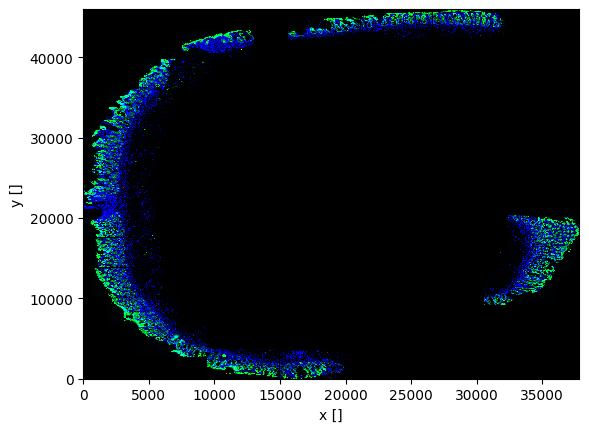

In [50]:
import matplotlib.pyplot as plt

# Visualize the DataArray using xarray's built-in imshow function
ax = stitched_image.plot.imshow(cmap="viridis", add_colorbar=True)
#ax.set_title("My DataArray Plot")
plt.show()


In [ ]:
sdata['1_image'].transform['global']

Affine (x, y -> x, y)
    [ 1.00000000e+00 -1.37253336e-16  1.71555556e+04]
    [-1.40753753e-16  1.00000000e+00  1.69755556e+05]
    [0. 0. 1.]

In [ ]:
sdata['1_image'].transform['global']

In [9]:
from spatial_image import to_spatial_image
from spatialdata import SpatialData
import xarray as xr
import numpy as np

# Example for stitching
stitched_image = np.zeros((3, H_total, W_total))  # e.g. (3, 3648 * 5, 5472 * 4)
# Place each tile in its correct (row, col) position
stitched_image[:, r*3648:(r+1)*3648, c*5472:(c+1)*5472] = image_tile

# Wrap in DataArray
stitched_da = xr.DataArray(stitched_image, dims=("c", "y", "x"))
image = to_spatial_image(stitched_da, scale=[1.0, 1.0])


NameError: name 'H_total' is not defined